In [16]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from dotenv import find_dotenv, load_dotenv

from utils import analysis_utils, isku_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)

<module 'utils.isku_utils' from '/home/emily_zuetell/projects/poreallas/utils/isku_utils.py'>

In [17]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

# Define Forecast
EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]

In [30]:
RUN_MONTH = "2026-10"
N_LEADS = 6

_months = pd.period_range(pd.Period(RUN_MONTH, "M"), periods=N_LEADS, freq="M")
FC_MONTHS = [p.month for p in _months]
FC_PERIOD = slice(
    _months[0].start_time.strftime("%Y-%m-%d"),
    _months[-1].end_time.strftime("%Y-%m-%d"),
)

# Baseline period for Impact
BASELINE_PERIOD = slice("1996-01-01", "2025-12-31")


config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [31]:
# Projection Effects
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)

In [32]:
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months)

In [33]:
mmt = effect["/fixed_beta"]["mmt"].sel(age_cohort="age65plus").mean(dim="sample")

In [41]:
### Seasonal Forecast ###
forecast = xr.open_zarr(
    "../data/v2610/v20261006_parsed_forecast.zarr"
)  # Daily ensemble member temp
hindcast = xr.open_zarr(
    "../data/v2610/v20261006_parsed_hindcast.zarr"
)  # Daily ensemble mean temp
forecast_ir = isku_utils.grid_to_ir(forecast, savefile=None)
hindcast_ir = isku_utils.grid_to_ir(hindcast, savefile=None)
# Monthly avg temp
forecast_avg = forecast.groupby("time.month").mean().sel(month=config.months)
hindcast_avg = hindcast.groupby("time.month").mean()
# Monthly anomaly relative to 1996-2025 climatological baseline
fc_anomaly = forecast_avg["tas"] - hindcast_avg["tas"]
fc_anom_ir = isku_utils.grid_to_ir(fc_anomaly.mean(dim="number"), savefile=None)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfull

In [42]:
### Change in Days > Avg MMT ###
da_fc = forecast_ir.mean(dim="number")
counts_fc = (
    (da_fc["tas"] > (273 + mmt.mean()))
    .resample(time="1MS")
    .sum()
    .groupby("time.month")
    .mean()
)

da_hc = hindcast_ir
counts_hc = (
    (da_hc["tas"] > (273 + mmt.mean()))
    .resample(time="1MS")
    .sum()
    .groupby("time.month")
    .mean()
)

counts = counts_fc - counts_hc

/tmp/ipykernel_290459/3346020700.py:5: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.merge([a.rename("a"), b.rename("b")], join="inner")
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Text(0, 0.5, 'Impact: Monthly Mortality Rate')

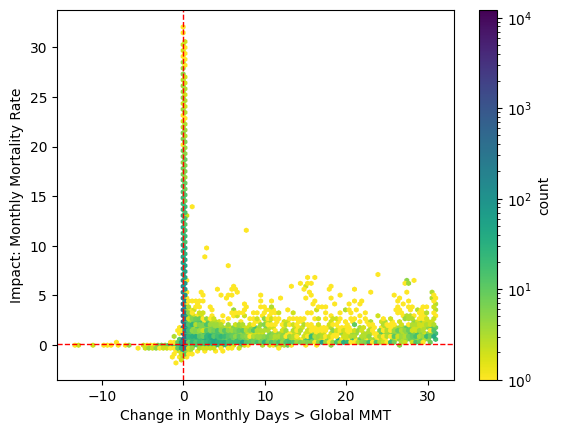

In [50]:
fig, ax = plt.subplots()
a = counts.sel(month=3)
b = impact.mean(dim=["number", "sample"]).sel(month=3)

ds = xr.merge([a.rename("a"), b.rename("b")], join="inner")

x = ds["a"].values.ravel()
y = ds["b"].values.ravel()

plt.hexbin(
    ds["a"].values.ravel(),
    ds["b"].values.ravel(),
    gridsize=100,
    bins="log",
    mincnt=1,
    cmap="viridis_r",
)
plt.colorbar(label="count")

ax.axvline(np.nanpercentile(x, 50), color="red", linestyle="--", linewidth=1)
ax.axhline(np.nanpercentile(y, 50), color="red", linestyle="--", linewidth=1)

plt.xlabel("Change in Monthly Days > Global MMT")
plt.ylabel("Impact: Monthly Mortality Rate")

(0.0, 40.0)

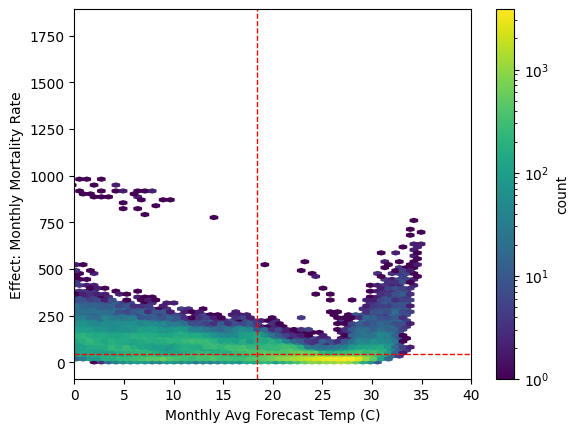

In [ ]:
## Forecast vs Effect (Not Impact)
fig, ax = plt.subplots()
a = forecast_ir["tas"].groupby("time.month").mean() - 273.15
# b = impact.mean(dim = ['number', 'sample'])
b = (
    effect["/forecast"]["effect"]
    .chunk({dim: -1 for dim in config.dims})
    .chunk({"region": "auto"})
    .sel(age_cohort="age65plus")
    .groupby("time.month")
    .sum()
    .mean(dim=["number", "sample"])
)

ds = xr.merge([a.rename("a"), b.rename("b")], join="inner")

x = ds["a"].values.ravel()
y = ds["b"].values.ravel()

hb = ax.hexbin(x, y, gridsize=100, bins="log", mincnt=1)

ax.axvline(np.nanpercentile(x, 50), color="red", linestyle="--", linewidth=1)
ax.axhline(np.nanpercentile(y, 50), color="red", linestyle="--", linewidth=1)

fig.colorbar(hb, ax=ax, label="count")
ax.set_xlabel("Monthly Avg Forecast Temp (C)")
ax.set_ylabel("Effect: Monthly Mortality Rate")
ax.set_xlim([0, 40])